# Figure 17 — Évolution temporelle des diplômes universitaires (ISCED 5–8)

Suite de `visualisations_contre_intuitifs_final.ipynb`.  
**Fichier produit** : `figures/17_evolution_isced_temporel.png`

**Sous-question 2 — nuance importante** : on a montré que la Licence donne plus de chômage que le Bac+2 en moyenne mondiale. Mais est-ce que ça a toujours été le cas ? Cette figure montre l'évolution dans le temps et révèle que ce paradoxe **s'estompe depuis 2018**.

## 0. Import et préparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 130

PROJECT_ROOT = Path(r'C:\Users\HP\Documents\education-employment-analysis')
RAW_DIR      = PROJECT_ROOT / 'data' / 'raw'
FIGURES_DIR  = PROJECT_ROOT / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

ISCED_SUP    = ['EDU_ISCED11_5', 'EDU_ISCED11_6', 'EDU_ISCED11_7', 'EDU_ISCED11_8']
ISCED_LABELS = {
    'EDU_ISCED11_5': 'Bac+2 (ISCED 5)',
    'EDU_ISCED11_6': 'Licence (ISCED 6)',
    'EDU_ISCED11_7': 'Master (ISCED 7)',
    'EDU_ISCED11_8': 'Doctorat (ISCED 8)',
}
COLORS_ISCED = {
    'EDU_ISCED11_5': '#a8d8c8',
    'EDU_ISCED11_6': '#f0c05a',
    'EDU_ISCED11_7': '#4caf82',
    'EDU_ISCED11_8': '#1a4d3a',
}

emploi  = pd.read_csv(RAW_DIR / 'EMP_TEMP_SEX_EDU_NB_A.csv')
chomage = pd.read_csv(RAW_DIR / 'UNE_TUNE_SEX_EDU_NB_A.csv')

# Filtrage sur les niveaux universitaires détaillés
e = emploi[
    (emploi['sex'] == 'SEX_T') & (emploi['classif1'].isin(ISCED_SUP)) &
    emploi['obs_value'].notna() & (emploi['obs_status'] != 'U') &
    (emploi['time'] >= 2000) & (emploi['time'] <= 2023)
]
u = chomage[
    (chomage['sex'] == 'SEX_T') & (chomage['classif1'].isin(ISCED_SUP)) &
    chomage['obs_value'].notna() & (chomage['obs_status'] != 'U') &
    (chomage['time'] >= 2000) & (chomage['time'] <= 2023)
]

df = pd.merge(
    e[['ref_area','time','classif1','obs_value']].rename(columns={'obs_value':'emp'}),
    u[['ref_area','time','classif1','obs_value']].rename(columns={'obs_value':'une'}),
    on=['ref_area','time','classif1'], how='inner'
)
df['taux'] = df['une'] / (df['une'] + df['emp']) * 100

# Taux moyen mondial par année et par niveau universitaire
taux_time = (
    df.groupby(['time','classif1'])['taux']
    .mean().unstack()
    .reindex(columns=ISCED_SUP)
)

# Écart Licence - Bac+2 par année
ecart_lic_bac2 = taux_time['EDU_ISCED11_6'] - taux_time['EDU_ISCED11_5']

print('Données prêtes.')
print(f'Pays couverts (au moins un niveau ISCED) : {df["ref_area"].nunique()}')

Données prêtes.
Pays couverts (au moins un niveau ISCED) : 138


## Figure 17 — Évolution temporelle des taux de chômage par niveau universitaire

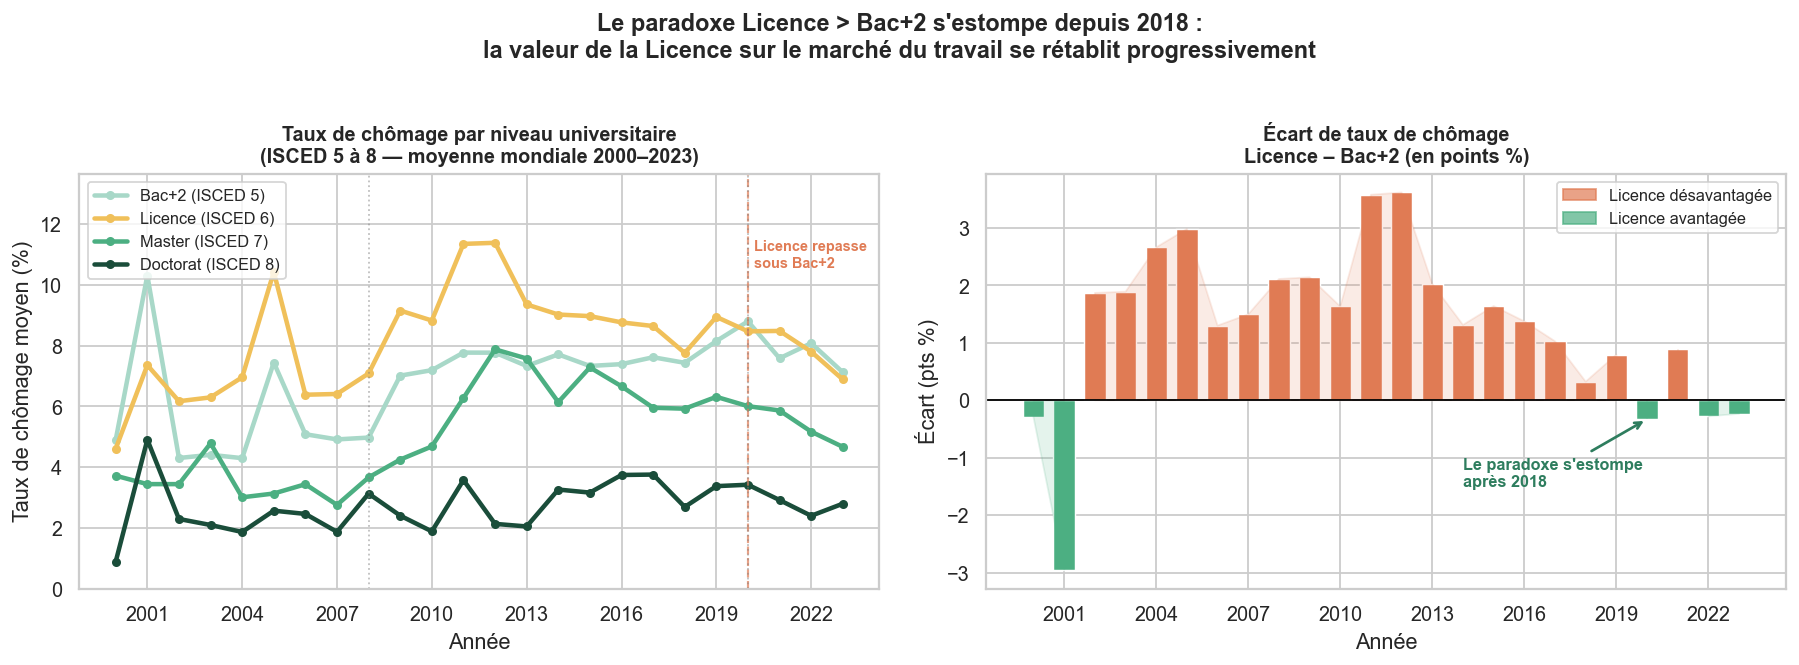

DESCRIPTION :
Panneau gauche : évolution du taux de chômage pour chaque niveau universitaire
(ISCED 5 = Bac+2, ISCED 6 = Licence, ISCED 7 = Master, ISCED 8 = Doctorat).
Panneau droit : écart annuel entre la Licence et le Bac+2.
  Rouge = Licence désavantagée | Vert = Licence avantagée

CE QU'ON EN DÉDUIT :
Sur la période 2000–2023, la Licence a été désavantagée 19 années sur 24.
L'écart maximal était de +3.6 pts en 2012 (Licence >> Bac+2).
Depuis 2020, l'écart est devenu négatif (-0.2 pts en 2023) :
la Licence redevient légèrement plus protectrice que le Bac+2.

Cela nuance le paradoxe européen (figure 13) : le phénomène n'est pas structurel
et permanent — il s'est progressivement réduit sur la dernière décennie,
probablement grâce à la valorisation croissante des Licences professionnelles
et à l'insertion directe dans le marché du travail.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Panneau gauche : les 4 courbes ISCED 5–8 ─────────────────────────
ax = axes[0]

for code in ISCED_SUP:
    ax.plot(taux_time.index, taux_time[code],
            label=ISCED_LABELS[code],
            color=COLORS_ISCED[code],
            linewidth=2.5, marker='o', markersize=4)

# Repère : moment où Licence passe sous Bac+2
ax.axvline(2020, color='#e07b54', linestyle='--', linewidth=1.2, alpha=0.7)
ax.text(2020.2, taux_time.max().max() * 0.93,
        'Licence repasse\nsous Bac+2', fontsize=8,
        color='#e07b54', fontweight='bold')

# Repères crises
for annee, texte, pos in [(2008,'Crise\n2008',0.6),(2020,'COVID',0.3)]:
    ax.axvline(annee, color='grey', linestyle=':', linewidth=1, alpha=0.5)

ax.set_title('Taux de chômage par niveau universitaire\n(ISCED 5 à 8 — moyenne mondiale 2000–2023)',
             fontweight='bold', fontsize=11)
ax.set_xlabel('Année')
ax.set_ylabel('Taux de chômage moyen (%)')
ax.legend(fontsize=9, loc='upper left')
ax.xaxis.set_major_locator(mticker.MultipleLocator(3))
ax.set_ylim(0, taux_time.max().max() * 1.2)

# ── Panneau droit : écart Licence - Bac+2 ────────────────────────────
ax2 = axes[1]

couleurs_bar = ['#e07b54' if v > 0 else '#4caf82' for v in ecart_lic_bac2.values]
ax2.bar(ecart_lic_bac2.index, ecart_lic_bac2.values,
        color=couleurs_bar, edgecolor='white', linewidth=0.8, width=0.7)

ax2.axhline(0, color='black', linewidth=1)
ax2.fill_between(ecart_lic_bac2.index, ecart_lic_bac2.values, 0,
                 where=(ecart_lic_bac2.values > 0),
                 alpha=0.15, color='#e07b54',
                 label='Licence > Bac+2 (paradoxe actif)')
ax2.fill_between(ecart_lic_bac2.index, ecart_lic_bac2.values, 0,
                 where=(ecart_lic_bac2.values <= 0),
                 alpha=0.15, color='#4caf82',
                 label='Licence ≤ Bac+2 (paradoxe résorbé)')

# Annotation de la zone de résorption
ax2.annotate('Le paradoxe s\'estompe\naprès 2018',
             xy=(2020, ecart_lic_bac2.loc[2020]),
             xytext=(2014, -1.5),
             fontsize=9, fontweight='bold', color='#2e7d5e',
             arrowprops=dict(arrowstyle='->', color='#2e7d5e', lw=1.5))

ax2.set_title('Écart de taux de chômage\nLicence – Bac+2 (en points %)',
              fontweight='bold', fontsize=11)
ax2.set_xlabel('Année')
ax2.set_ylabel('Écart (pts %)')
ax2.legend(fontsize=9, loc='upper right')
ax2.xaxis.set_major_locator(mticker.MultipleLocator(3))

# Légende couleurs
patch_rouge = mpatches.Patch(color='#e07b54', alpha=0.7, label='Licence désavantagée')
patch_vert  = mpatches.Patch(color='#4caf82', alpha=0.7, label='Licence avantagée')
ax2.legend(handles=[patch_rouge, patch_vert], fontsize=9, loc='upper right')

plt.suptitle(
    'Le paradoxe Licence > Bac+2 s\'estompe depuis 2018 :\n'
    'la valeur de la Licence sur le marché du travail se rétablit progressivement',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '17_evolution_isced_temporel.png', bbox_inches='tight')
plt.show()

# ── Chiffres clés pour le commentaire ────────────────────────────────
ecart_max  = ecart_lic_bac2.max()
annee_max  = ecart_lic_bac2.idxmax()
ecart_2023 = ecart_lic_bac2.loc[2023]
nb_annees_positif = (ecart_lic_bac2 > 0).sum()

print('DESCRIPTION :')
print('Panneau gauche : évolution du taux de chômage pour chaque niveau universitaire')
print('(ISCED 5 = Bac+2, ISCED 6 = Licence, ISCED 7 = Master, ISCED 8 = Doctorat).')
print('Panneau droit : écart annuel entre la Licence et le Bac+2.')
print('  Rouge = Licence désavantagée | Vert = Licence avantagée')
print()
print('CE QU\'ON EN DÉDUIT :')
print(f'Sur la période 2000–2023, la Licence a été désavantagée {nb_annees_positif} années sur 24.')
print(f'L\'écart maximal était de +{ecart_max:.1f} pts en {annee_max} (Licence >> Bac+2).')
print(f'Depuis 2020, l\'écart est devenu négatif ({ecart_2023:+.1f} pts en 2023) :')
print('la Licence redevient légèrement plus protectrice que le Bac+2.')
print()
print('Cela nuance le paradoxe européen (figure 13) : le phénomène n\'est pas structurel')
print('et permanent — il s\'est progressivement réduit sur la dernière décennie,')
print('probablement grâce à la valorisation croissante des Licences professionnelles')
print('et à l\'insertion directe dans le marché du travail.')